In [14]:
# Import the required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [15]:
# Load the breast cancer dataset

data = load_breast_cancer()

# Convert the dataset into a Pandas DataFrame
df = pd.DataFrame(data.data, columns=data.feature_names)

# Add the target column
df["diagnosis"] = data.target

# Display the first five rows
print("First five rows of the dataset:")
display(df.head())

First five rows of the dataset:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [16]:
# Explore the dataset

# 1. Display the dataset shape
print("Dataset Shape:", df.shape)

# 2. Display column names
print("\nColumn Names:")
print(df.columns.tolist())

# 3. Display dataset information
print("\nDataset Information:")
df.info()

# 4. Check for missing values
print("\nMissing Values:")
print(df.isnull().sum().sum())

# 5. Display statistical information
print("\nStatistical Summary:")
display(df.describe())

Dataset Shape: (569, 31)

Column Names:
['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension', 'diagnosis']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter         

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,0.627417
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,0.483918
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,0.000000
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,0.000000
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,1.000000
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,1.000000
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,1.000000


Diagnosis Distribution:
Malignant    212
Benign       357
Name: count, dtype: int64


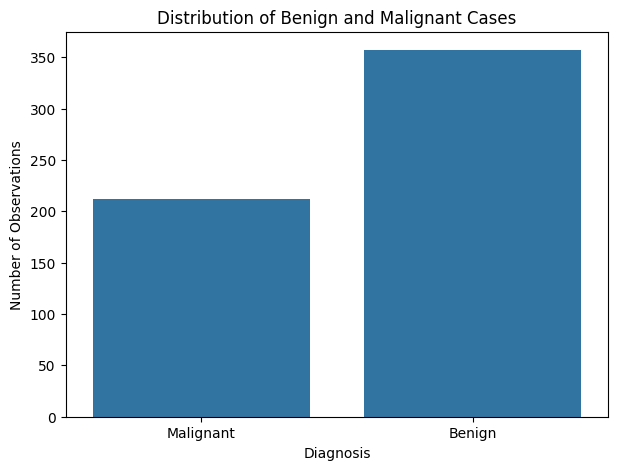

In [17]:
# Count the number of observations in each diagnosis category

diagnosis_counts = df["diagnosis"].value_counts().sort_index()

# Convert numerical labels into readable names
diagnosis_counts.index = ["Malignant", "Benign"]

# Display the counts
print("Diagnosis Distribution:")
print(diagnosis_counts)

# Create a bar chart
plt.figure(figsize=(7, 5))

sns.barplot(
    x=diagnosis_counts.index,
    y=diagnosis_counts.values
)

plt.title("Distribution of Benign and Malignant Cases")
plt.xlabel("Diagnosis")
plt.ylabel("Number of Observations")

plt.show()

In [18]:
# Separate input features and target

X = df.drop("diagnosis", axis=1)
y = df["diagnosis"]

# Display the shapes
print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

# Display the first five input observations
print("\nFirst five observations of X:")
display(X.head())

# Display the first five target values
print("\nFirst five target values:")
print(y.head())

Features Shape: (569, 30)
Target Shape: (569,)

First five observations of X:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678



First five target values:
0    0
1    0
2    0
3    0
4    0
Name: diagnosis, dtype: int64


In [19]:
# Split the dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Display the sizes of the datasets
print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (455, 30)
Testing Features: (114, 30)

Training Target: (455,)
Testing Target: (114,)


In [20]:
# Create a StandardScaler object

scaler = StandardScaler()

# Fit the scaler on training data and transform it
X_train_scaled = scaler.fit_transform(X_train)

# Transform the testing data using the same scaler
X_test_scaled = scaler.transform(X_test)

# Display the shapes
print("Scaled Training Data Shape:", X_train_scaled.shape)
print("Scaled Testing Data Shape:", X_test_scaled.shape)

print("\nFeature scaling completed successfully!")

Scaled Training Data Shape: (455, 30)
Scaled Testing Data Shape: (114, 30)

Feature scaling completed successfully!


In [21]:
# Create the Logistic Regression model

model = LogisticRegression(max_iter=5000)

# Train the model using the training data
model.fit(X_train_scaled, y_train)

print("Medical Diagnosis AI model trained successfully!")

Medical Diagnosis AI model trained successfully!


In [22]:
# Predict diagnoses using the trained model

y_pred = model.predict(X_test_scaled)

# Display actual and predicted diagnoses
results = pd.DataFrame({
    "Actual Diagnosis": y_test.values,
    "Predicted Diagnosis": y_pred
})

print("First 10 Actual and Predicted Diagnoses:")
display(results.head(10))

First 10 Actual and Predicted Diagnoses:


,Actual Diagnosis,Predicted Diagnosis
0,0,0
1,1,1
2,0,0
3,1,1
4,0,0
5,1,1
6,1,1
7,0,0
8,0,0
9,0,0


In [23]:
# Evaluate the model using a classification report

print("Classification Report:\n")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Malignant", "Benign"]
    )
)

Classification Report:

              precision    recall  f1-score   support

   Malignant       0.98      0.98      0.98        42
      Benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



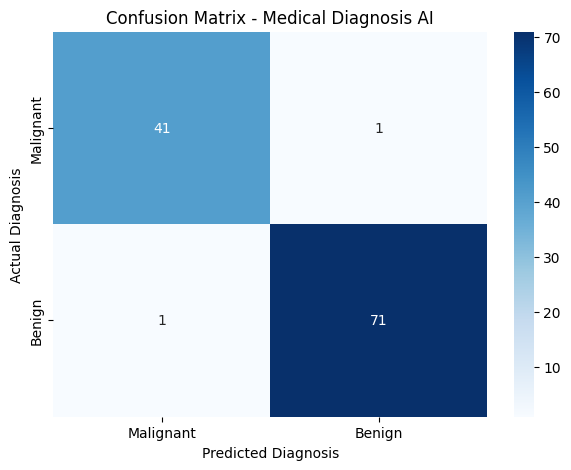

In [24]:
# Create the confusion matrix

cm = confusion_matrix(y_test, y_pred)

# Visualize the confusion matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Malignant", "Benign"],
    yticklabels=["Malignant", "Benign"]
)

plt.title("Confusion Matrix - Medical Diagnosis AI")
plt.xlabel("Predicted Diagnosis")
plt.ylabel("Actual Diagnosis")

plt.show()


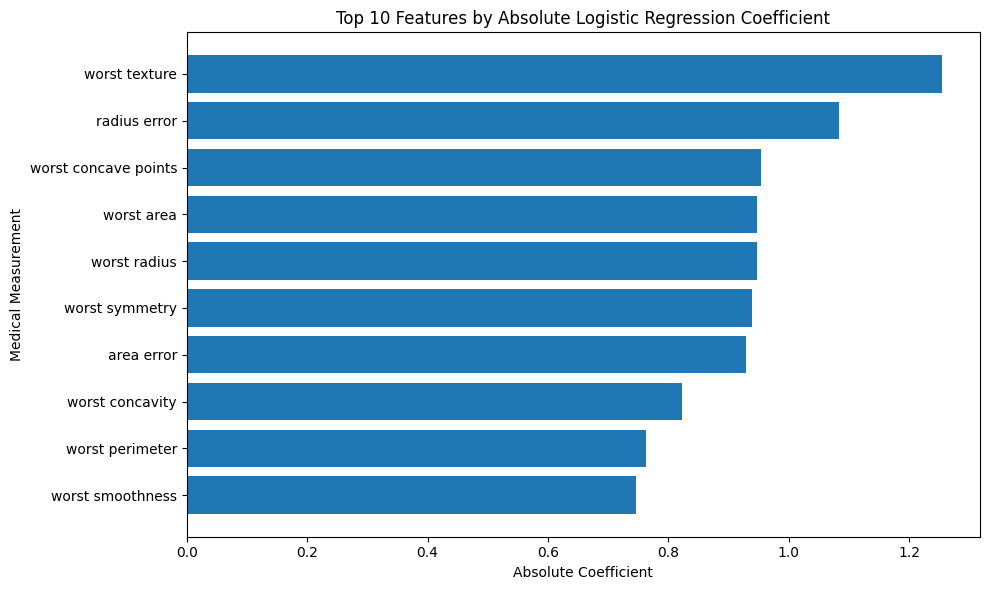

In [25]:
# Analyze the Logistic Regression model coefficients

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_[0]
})

# Calculate the absolute coefficient values
feature_importance["Absolute Coefficient"] = (
    feature_importance["Coefficient"].abs()
)

# Select the 10 features with the largest absolute coefficients
top_features = feature_importance.nlargest(
    10, "Absolute Coefficient"
).sort_values("Absolute Coefficient")

# Create a horizontal bar chart
plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["Absolute Coefficient"]
)

plt.title("Top 10 Features by Absolute Logistic Regression Coefficient")
plt.xlabel("Absolute Coefficient")
plt.ylabel("Medical Measurement")

plt.tight_layout()
plt.show()

In [26]:
# Final Model Evaluation

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

# Display the results
print("=" * 45)
print("MEDICAL DIAGNOSIS AI - FINAL EVALUATION")
print("=" * 45)

print(f"Algorithm Used       : Logistic Regression")
print(f"Dataset Size         : {len(df)} observations")
print(f"Number of Features   : {X.shape[1]}")
print(f"Training Samples     : {len(X_train)}")
print(f"Testing Samples      : {len(X_test)}")

print("-" * 45)

print(f"Accuracy             : {accuracy * 100:.2f}%")
print(f"Precision (Benign)   : {precision:.4f}")
print(f"Recall (Benign)      : {recall:.4f}")
print(f"F1-Score (Benign)    : {f1:.4f}")

print("=" * 45)

MEDICAL DIAGNOSIS AI - FINAL EVALUATION
Algorithm Used       : Logistic Regression
Dataset Size         : 569 observations
Number of Features   : 30
Training Samples     : 455
Testing Samples      : 114
---------------------------------------------
Accuracy             : 98.25%
Precision (Benign)   : 0.9861
Recall (Benign)      : 0.9861
F1-Score (Benign)    : 0.9861


Conclusion

The Medical Diagnosis AI project demonstrates the use of machine learning for medical data classification. The Breast Cancer Wisconsin dataset was used to develop a Logistic Regression model that classifies observations as benign or malignant based on 30 numerical features.

The dataset was explored and divided into training and testing sets. Feature scaling was applied before training the model. Its performance was evaluated using accuracy, precision, recall, F1-score, and a confusion matrix.

Visualizations were also created to examine the distribution of diagnoses, model coefficients, and predicted versus actual class counts.

This project demonstrates how Python and machine learning can be used to analyze medical data and build a classification model. However, the model is intended for educational purposes only and must not be used to diagnose patients or make clinical decisions.